# When the normal approximation to the binomial fails

[Open in Colab](https://colab.research.google.com/github/andreasmang/stan/blob/main/demos/binomial-normal.ipynb) &nbsp;·&nbsp; nothing to install &nbsp;·&nbsp; **Runtime > Run all** takes a few seconds

Let $X\sim\text{Binomial}(n,p)$ count the successes in $n$ trials and let $\widehat p = X/n$ be the
sample proportion. The CLT says that $\widehat p$ is approximately $\mathcal N\big(p,\,p(1-p)/n\big)$,
and the Wald interval $\widehat p \pm 1.96\,\widehat{\text{se}}$ with $\widehat{\text{se}} = \sqrt{\widehat p(1-\widehat p)/n}$
is built on that approximation.

Why do probabilities near $0$ or $1$ matter? For a given sample size they can make the binomial
distribution highly skewed and concentrated near its boundary, and a symmetric normal distribution
is then a poor approximation. For example, if $n=100$ and $p=0.01$, the expected number of successes
is only $np = 1$, and

$$\mathbb P(X=0) = 0.99^{100} \approx 0.366 .$$

So even with $100$ trials, more than a third of samples contain no successes. The sample proportion
is far from normally distributed, and an observed proportion of zero gives a misleading plug-in
variance estimate of zero. This notebook shows all three effects.

In [1]:
from math import comb
import numpy as np, matplotlib.pyplot as plt

rng = np.random.default_rng(166)
n = 100          # number of trials
z = 1.96         # for a 95 percent interval

def binom_pmf(n, p):
    # P(X = k) for k = 0, 1, ..., n
    return np.array([comb(n, k) * p**k * (1 - p)**(n - k) for k in range(n + 1)])

def Phi(x):
    # standard normal CDF, without scipy
    from math import erf, sqrt
    return 0.5 * (1 + erf(x / sqrt(2)))

## 1. The numbers

With $p = 0.01$ the expected count is $1$, and most of the probability sits at $0$ and $1$ successes.
The normal approximation, on the other hand, puts mass on negative proportions, which are impossible.

In [2]:
p = 0.01
pmf = binom_pmf(n, p)
se = np.sqrt(p * (1 - p) / n)
print(f"n = {n}, p = {p}:  expected number of successes n p = {n * p:.0f}")
for k in range(5):
    print(f"  P(X = {k}) = {pmf[k]:.3f}")
print(f"  P(X >= 5) = {pmf[5:].sum():.4f}")
print(f"normal approximation: P(p_hat < 0) = Phi(-p/se) = {Phi(-p / se):.3f}")

n = 100, p = 0.01:  expected number of successes n p = 1
  P(X = 0) = 0.366
  P(X = 1) = 0.370
  P(X = 2) = 0.185
  P(X = 3) = 0.061
  P(X = 4) = 0.015
  P(X >= 5) = 0.0034
normal approximation: P(p_hat < 0) = Phi(-p/se) = 0.157


## 2. The distribution of $\widehat p$ against its normal approximation

The bars are the exact probabilities $\mathbb P(\widehat p = k/n)$, scaled by $n$ so that they have
total area $1$, like a density; the black curve is the normal density with the same mean and variance.
For $p = 0.5$ (left) the two agree. For $p = 0.01$ (right) the exact distribution is piled up against
the boundary $0$ and has a long right tail, while the normal curve is symmetric and spills over
into $\widehat p < 0$.

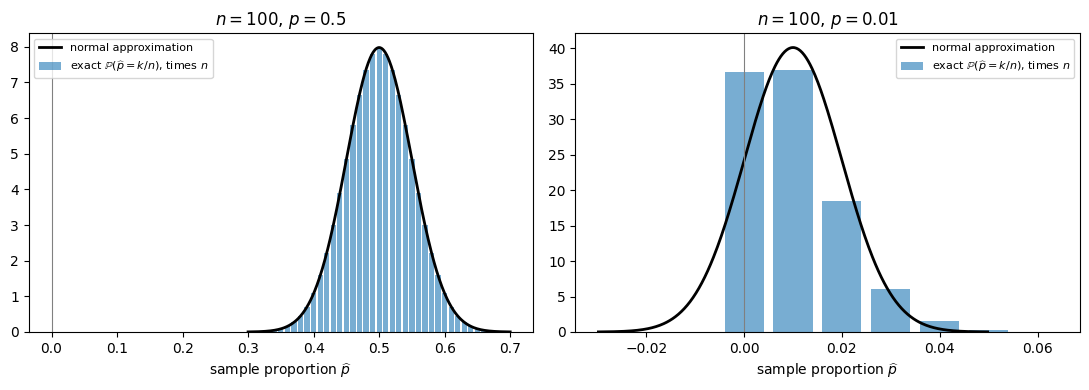

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, p in zip(axes, [0.5, 0.01]):
    pmf = binom_pmf(n, p)
    se = np.sqrt(p * (1 - p) / n)
    k = np.arange(n + 1)
    keep = pmf > 1e-4                               # only the values with visible probability
    ax.bar(k[keep] / n, pmf[keep] * n, width=0.8 / n, color="C0", alpha=0.6,
           label="exact $\\mathbb{P}(\\widehat p = k/n)$, times $n$")
    grid = np.linspace(p - 4 * se, p + 4 * se, 400)
    dens = np.exp(-0.5 * ((grid - p) / se)**2) / (se * np.sqrt(2 * np.pi))
    ax.plot(grid, dens, "k", lw=2, label="normal approximation")
    ax.axvline(0, color="gray", lw=0.8)
    ax.set_title(f"$n = {n}$, $p = {p}$")
    ax.set_xlabel("sample proportion $\\widehat p$")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 3. Many samples: zero successes, a zero standard error, and the Wald interval

Simulate $100{,}000$ samples of size $n = 100$. Whenever $X = 0$, the estimate is $\widehat p = 0$, the
plug-in standard error $\sqrt{\widehat p(1-\widehat p)/n}$ is $0$, and the Wald interval collapses to the
single point $\{0\}$, which does not contain $p$. The interval claims certainty exactly when the data
say least.

In [4]:
trials = 100_000
for p in [0.5, 0.01]:
    x = rng.binomial(n, p, size=trials)            # number of successes in each sample
    phat = x / n
    se_hat = np.sqrt(phat * (1 - phat) / n)        # plug-in estimate of the standard error
    covered = (phat - z * se_hat <= p) & (p <= phat + z * se_hat)
    print(f"p = {p}:")
    print(f"  fraction of samples with p_hat = 0:        {np.mean(x == 0):.3f}")
    print(f"  fraction with estimated standard error 0:  {np.mean(se_hat == 0):.3f}")
    print(f"  coverage of the 95% Wald interval:         {np.mean(covered):.3f}")

p = 0.5:
  fraction of samples with p_hat = 0:        0.000
  fraction with estimated standard error 0:  0.000
  coverage of the 95% Wald interval:         0.942
p = 0.01:
  fraction of samples with p_hat = 0:        0.367
  fraction with estimated standard error 0:  0.367
  coverage of the 95% Wald interval:         0.633


For $p = 0.5$ the Wald interval covers $p$ about $95$ percent of the time, as advertised. For
$p = 0.01$ it covers $p$ only about $63$ percent of the time: it fails on every sample with no
successes, and those alone are $37$ percent of all samples.

## 4. Coverage across all $p$

The coverage of the Wald interval can be computed exactly, by adding up $\mathbb P(X = k)$ over the
counts $k$ whose interval contains $p$. For $n = 100$ it is close to $95$ percent in the middle and
falls apart as $p$ approaches $0$ or $1$. (The jagged shape comes from $X$ being discrete.)

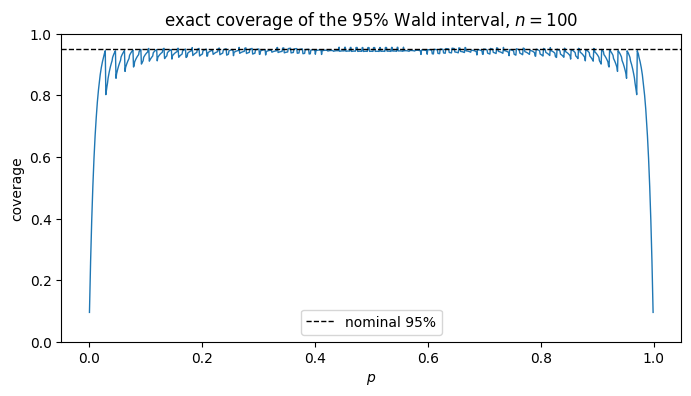

coverage at p = 0.01: 0.633
coverage at p = 0.5:  0.943


In [5]:
def wald_coverage(n, p):
    k = np.arange(n + 1)
    phat = k / n
    se_hat = np.sqrt(phat * (1 - phat) / n)
    covers = (phat - z * se_hat <= p) & (p <= phat + z * se_hat)
    return binom_pmf(n, p)[covers].sum()

pgrid = np.linspace(0.001, 0.999, 999)
cov = [wald_coverage(n, p) for p in pgrid]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(pgrid, cov, color="C0", lw=1)
ax.axhline(0.95, color="k", ls="--", lw=1, label="nominal 95%")
ax.set_xlabel("$p$")
ax.set_ylabel("coverage")
ax.set_title(f"exact coverage of the 95% Wald interval, $n = {n}$")
ax.set_ylim(0, 1)
ax.legend()
plt.show()
print(f"coverage at p = 0.01: {wald_coverage(n, 0.01):.3f}")
print(f"coverage at p = 0.5:  {wald_coverage(n, 0.5):.3f}")

A common rule of thumb asks for at least about $10$ expected successes and $10$ expected failures,
$np\ge 10$ and $n(1-p)\ge 10$, before trusting the normal approximation. For $n = 100$ that means
$0.1\le p\le 0.9$. There the coverage stays above about $93$ percent; below $p = 0.05$ it drops
under $88$ percent, and at $p = 0.01$ it is $63$ percent.

## Things to try

* Change `n` to $1000$ and rerun. How small can $p$ be before the coverage drops below $90$ percent?
* Keep $np = 1$ but vary $n$ (for example $n = 10, 100, 1000$ with $p = 1/n$). Does $\mathbb P(X = 0)$
  change much? Compare it with $e^{-1}\approx 0.368$.
* In section 4, replace $z = 1.96$ with $z = 2.58$ (a 99 percent interval). Does a wider interval fix
  the problem for $p = 0.01$?

---

This notebook is part of [STAN](https://github.com/andreasmang/stan), the code repository
for MATH 166 (Statistics) at Tufts University. The normal-based interval and the Wald test are in
Chapters 9 and 10 of Wasserman, *All of Statistics*.